# Phase 7: Collinearity and PCA
NHANES August 2021 to August 2023 (CBC, HbA1c, demographics).

In [1]:
%pip install pandas numpy scikit-learn statsmodels matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

os.makedirs("figures", exist_ok=True)

In [3]:
BASE = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/"
demo = pd.read_sas(BASE + "DEMO_L.xpt", format="xport")
cbc  = pd.read_sas(BASE + "CBC_L.xpt",  format="xport")
ghb  = pd.read_sas(BASE + "GHB_L.xpt",  format="xport")

df = demo.merge(cbc, on="SEQN").merge(ghb, on="SEQN")
print(df.shape)

(7199, 51)


In [4]:
df["DMDEDUC2"] = df["DMDEDUC2"].replace({7: np.nan, 9: np.nan})

df = df.dropna(subset=["LBXGH"])
y = (df["LBXGH"] >= 5.7).astype(int)

cbc_numeric_cols = [c for c in [
    "LBXWBCSI", "LBXLYPCT", "LBXMOPCT", "LBXNEPCT", "LBXEOPCT", "LBXBAPCT",
    "LBXRBCSI", "LBXHGB", "LBXHCT", "LBXMCVSI", "LBXMCHSI", "LBXMC",
    "LBXRDW", "LBXPLTSI", "LBXMPSI",
] if c in df.columns]

X = df[["RIAGENDR", "RIDRETH3", "DMDEDUC2"] + cbc_numeric_cols]
print(X.shape, y.mean())

(6715, 18) 0.3516008935219658


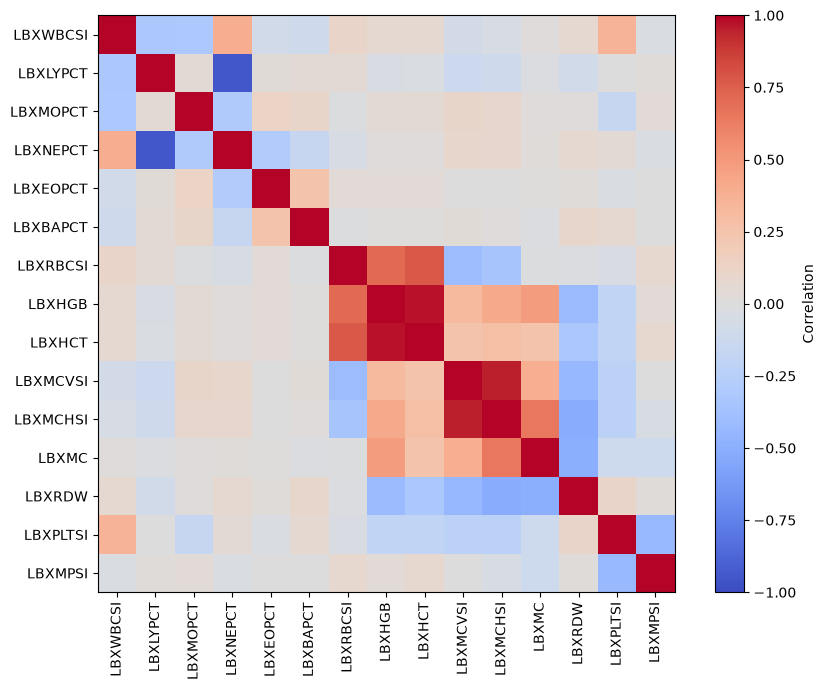

LBXNEPCT    28243.3
LBXLYPCT    23994.0
LBXMOPCT     1410.7
LBXEOPCT     1395.7
LBXHCT        932.0
LBXMCHSI      854.0
LBXHGB        788.5
LBXMCVSI      731.9
LBXRBCSI      135.3
LBXMC          89.5
LBXBAPCT       35.9
LBXRDW          1.7
LBXPLTSI        1.7
LBXWBCSI        1.5
LBXMPSI         1.3
dtype: float64


In [5]:
num = df[cbc_numeric_cols].dropna()
corr = num.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, label="Correlation")
plt.tight_layout()
plt.savefig("figures/cbc_corr_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

def vif_table(data):
    Xc = add_constant(data)
    vals = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
    return pd.Series(vals, index=data.columns).sort_values(ascending=False).round(1)

print(vif_table(num))

In [6]:
reduced_cols = [c for c in cbc_numeric_cols if c != "LBXNEPCT"]
print(vif_table(df[reduced_cols].dropna()))

LBXHCT      931.7
LBXMCHSI    853.9
LBXHGB      788.2
LBXMCVSI    731.8
LBXRBCSI    135.3
LBXMC        89.5
LBXRDW        1.7
LBXPLTSI      1.7
LBXWBCSI      1.5
LBXMPSI       1.3
LBXLYPCT      1.2
LBXMOPCT      1.2
LBXBAPCT      1.1
LBXEOPCT      1.1
dtype: float64


Components for 90% variance: 9; for 95%: 10


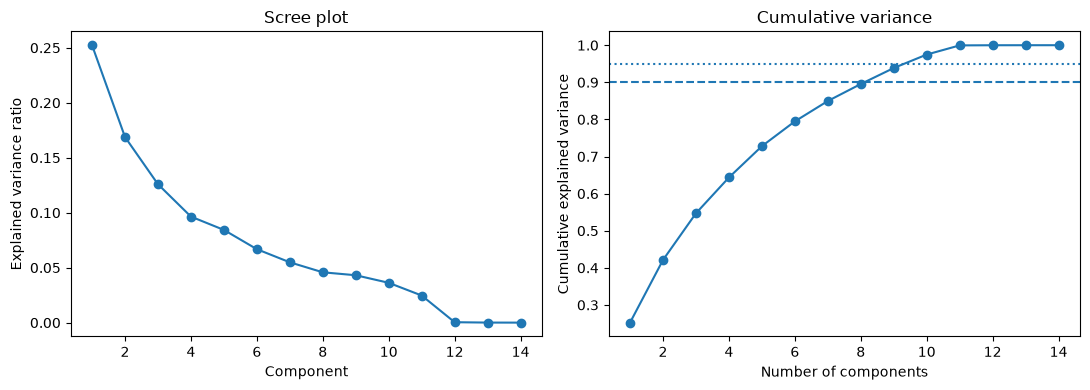

In [7]:
prep = Pipeline([("imp", SimpleImputer(strategy="median")),
                 ("sc", StandardScaler())])
Xs = prep.fit_transform(df[reduced_cols])

pca_full = PCA().fit(Xs)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n90 = int(np.argmax(cum >= 0.90) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Components for 90% variance: {n90}; for 95%: {n95}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(evr) + 1), evr, marker="o")
ax[0].set_xlabel("Component")
ax[0].set_ylabel("Explained variance ratio")
ax[0].set_title("Scree plot")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o")
ax[1].axhline(0.90, linestyle="--")
ax[1].axhline(0.95, linestyle=":")
ax[1].set_xlabel("Number of components")
ax[1].set_ylabel("Cumulative explained variance")
ax[1].set_title("Cumulative variance")
plt.tight_layout()
plt.savefig("figures/pca_scree.png", dpi=200, bbox_inches="tight")
plt.show()

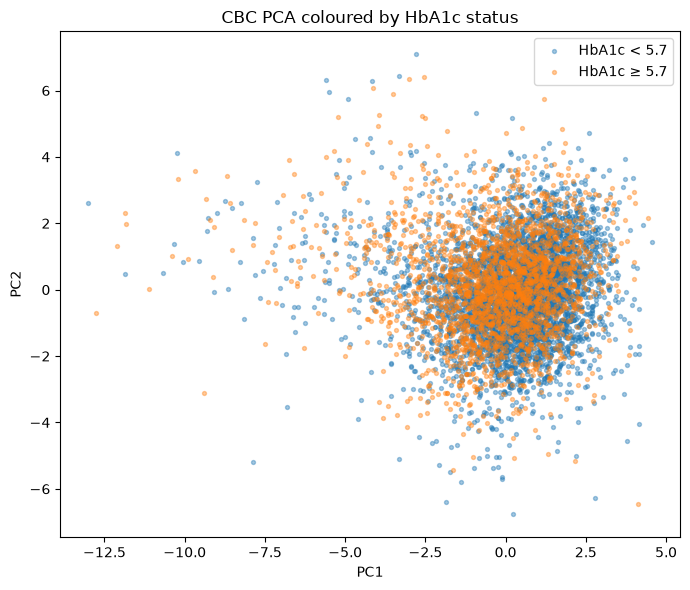

In [8]:
pcs = PCA(n_components=2).fit_transform(Xs)

fig, ax = plt.subplots(figsize=(7, 6))
for label, name in [(0, "HbA1c < 5.7"), (1, "HbA1c ≥ 5.7")]:
    mask = (y.values == label)
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=8, alpha=0.4, label=name)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("CBC PCA coloured by HbA1c status")
ax.legend()
plt.tight_layout()
plt.savefig("figures/pca_pc1_pc2.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
edu_order = [[1.0, 2.0, 3.0, 4.0, 5.0]]

In [10]:
def make_preprocessor_v2(num_cols, use_pca):
    num_steps = [("imp", SimpleImputer(strategy="median")),
                 ("sc", StandardScaler())]
    if use_pca:
        num_steps.append(("pca", PCA(n_components=0.90)))

    return ColumnTransformer([
        ("sex",  Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                           ("enc", OneHotEncoder(drop="if_binary"))]), ["RIAGENDR"]),
        ("race", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                           ("enc", OneHotEncoder(handle_unknown="ignore"))]), ["RIDRETH3"]),
        ("edu",  Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                           ("enc", OrdinalEncoder(categories=edu_order,
                                                  handle_unknown="use_encoded_value",
                                                  unknown_value=-1))]), ["DMDEDUC2"]),
        ("num",  Pipeline(num_steps), num_cols),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for arm, use_pca in [("raw CBC", False), ("PCA CBC", True)]:
    for name, clf in [("logreg", LogisticRegression(max_iter=1000)),
                      ("rf", RandomForestClassifier(n_estimators=200, random_state=42))]:
        pipe = Pipeline([("pre", make_preprocessor_v2(reduced_cols, use_pca)),
                         ("clf", clf)])
        scores = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
        print(f"{arm:8s} {name:7s} AUC = {scores.mean():.3f} ± {scores.std():.3f}")

raw CBC  logreg  AUC = 0.727 ± 0.009
raw CBC  rf      AUC = 0.732 ± 0.011
PCA CBC  logreg  AUC = 0.717 ± 0.011
PCA CBC  rf      AUC = 0.712 ± 0.011


## Phase 7 findings

**PCA.** After dropping neutrophil %, 9 of the 14 standardized CBC variables are needed to explain 90% of the variance (8 components reach about 89.5%), and 10 are needed for 95%. The cumulative variance reaches 100% at 11 components. The scree plot shows a first elbow at about component 4, but the clearest break is after component 11: components 12 to 14 explain essentially no variance. This matches the collinearity findings, since the six red cell variables contain only about three independent measurements (the rest are algebraically derived), so the 14 variables behave like about 11 dimensions. Outside the red cell block the variables are largely independent, which is why many components are needed to reach 90%.

The PC1 vs PC2 plot shows almost no separation by HbA1c status: participants with HbA1c ≥ 5.7 and < 5.7 overlap almost completely in one dense cloud, so the first two components do not distinguish the groups. The only visible difference is that the sparse far-left tail of PC1 (below about -7) appears to contain proportionally more HbA1c ≥ 5.7 points, but this involves few participants and was not tested. This is consistent with the modest AUC values (about 0.73) and with the PCA arm not improving prediction.